In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [4]:
np.random.seed(42)
n = 100

df = pd.DataFrame({
    'size': np.random.randint(50, 200, n),      # متراژ خانه
    'bedrooms': np.random.randint(1, 5, n),     # تعداد اتاق‌خواب
    'age': np.random.randint(0, 50, n),         # سن ساختمان
    'price': 0  # هدف
})

df['price'] = (df['size'] * 50) + (df['bedrooms'] * 10000) - (df['age'] * 500) + np.random.normal(0, 5000, n)

print(df.head())
print(df.shape)  # (100, 4)

   size  bedrooms  age         price
0   152         2   48   6434.470354
1   142         3   48  12277.497829
2    64         3   11  26985.045326
3   156         1   38 -10872.850978
4   121         3    1  36303.295217
(100, 4)


In [2]:
def linear_regression(x, w0, w1):
    y_hat= w1*x+w0
    return y_hat

In [3]:
def mse(y, y_hat):
    loss = np.mean((y-y_hat)**2)
    return loss

In [6]:
np.random.seed(42)

n = 100

X = np.random.uniform(0, 10, n)

y = 3 * X + 7 + np.random.normal(0, 2, n)

df = pd.DataFrame({
    'X': X,
    'y': y
})

In [7]:
train_set = np.array(df)
x_train = train_set[:,0]
y_train = train_set[:,1]

In [8]:
w0, w1=np.random.randn(),np.random.randn()
eta= 0.01
n_epocs = 10000

for epoch in range(n_epocs):
    y_hat= linear_regression(x_train,w0, w1)
    
    e=mse(y_train, y_hat)
    
    grad_w0=2 * np.mean(y_hat-y_train)
    grad_w1= 2 * np.mean(x_train*(y_hat-y_train))
    
    w0 -= eta*grad_w0
    w1 -= eta*grad_w1
    
    print(f'Epoch={epoch}, \t E={e:.4}, \t w1={w1:.4}')

Epoch=0, 	 E=225.0, 	 w1=3.049
Epoch=1, 	 E=45.25, 	 w1=3.633
Epoch=2, 	 E=20.76, 	 w1=3.844
Epoch=3, 	 E=17.3, 	 w1=3.918
Epoch=4, 	 E=16.71, 	 w1=3.941
Epoch=5, 	 E=16.5, 	 w1=3.946
Epoch=6, 	 E=16.34, 	 w1=3.945
Epoch=7, 	 E=16.2, 	 w1=3.94
Epoch=8, 	 E=16.05, 	 w1=3.935
Epoch=9, 	 E=15.91, 	 w1=3.93
Epoch=10, 	 E=15.77, 	 w1=3.924
Epoch=11, 	 E=15.63, 	 w1=3.918
Epoch=12, 	 E=15.49, 	 w1=3.913
Epoch=13, 	 E=15.36, 	 w1=3.907
Epoch=14, 	 E=15.22, 	 w1=3.902
Epoch=15, 	 E=15.09, 	 w1=3.896
Epoch=16, 	 E=14.96, 	 w1=3.891
Epoch=17, 	 E=14.83, 	 w1=3.885
Epoch=18, 	 E=14.7, 	 w1=3.88
Epoch=19, 	 E=14.58, 	 w1=3.874
Epoch=20, 	 E=14.45, 	 w1=3.869
Epoch=21, 	 E=14.33, 	 w1=3.864
Epoch=22, 	 E=14.2, 	 w1=3.858
Epoch=23, 	 E=14.08, 	 w1=3.853
Epoch=24, 	 E=13.96, 	 w1=3.848
Epoch=25, 	 E=13.84, 	 w1=3.843
Epoch=26, 	 E=13.73, 	 w1=3.838
Epoch=27, 	 E=13.61, 	 w1=3.832
Epoch=28, 	 E=13.49, 	 w1=3.827
Epoch=29, 	 E=13.38, 	 w1=3.822
Epoch=30, 	 E=13.27, 	 w1=3.817
Epoch=31, 	 E=13.16, 	 w1=

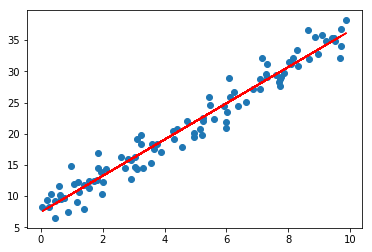

In [9]:
plt.scatter(x_train,y_train)
y_hat=linear_regression(x_train, w0, w1)
plt.plot(x_train,y_hat, 'r')

In [12]:
np.savetxt('linear_regression', np.array([w0,w1]))

In [13]:
w=np.loadtxt('linear_regression')
w0,w1=w[0],w[1]
print(w0,w1)

7.430192315093415 2.9080453545754064


In [14]:
def r2(y, y_hat):
    return 1-np.sum((y-y_hat)**2)/np.sum((y-y.mean())**2)

In [15]:
y_hat = linear_regression(x_train,w0, w1)
r2(y_train, y_hat)

0.958272869425565